# 07 · Track 2 — el corredor de rescate seguro

> **NO HAY NOMINACIÓN DE FÁRMACO EN ESTE NOTEBOOK, Y ES DELIBERADO.**
>
> Toda la evidencia citada tiene identificador **verificado en el proyecto**. Donde falta
> evidencia se escribe *hueco*, no una cita plausible.

## Pregunta

**¿Existe un mecanismo terapéutico plausible, falsable y seguro para este paciente?**

## La corrección que reorganiza todo

Agrupar la evidencia bajo «proteostasis» metía en la misma caja dos intervenciones con lógica
terapéutica distinta y **consecuencias oncológicas potencialmente opuestas**:

| | T2-A · aguas arriba | T2-B · aguas abajo |
|---|---|---|
| Cadena | variante → inestabilidad → **subir BUBR1** → mejor checkpoint | célula ya aneuploide → estrés → **subir HSP** → tolera mejor |
| Efecto buscado | **menos** células aneuploides nuevas | las que existen **viven mejor** |
| Riesgo | podría reducir CIN | podría aumentar la supervivencia de células inestables |

En un niño que ya tuvo un rabdomiosarcoma, **esa diferencia lo es todo**.

In [1]:
import sys, os, io, json, pickle, collections
os.chdir("..")                       # el pipeline usa rutas relativas a la raiz
sys.path.insert(0, ".")
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from src.nb import figlib as fl      # figuras inline + caption con procedencia
print("entorno listo · las figuras de este notebook aparecen INLINE, con caption")

entorno listo · las figuras de este notebook aparecen INLINE, con caption


## Resultado primario 1 · los ocho puentes

Toda afirmación declara **qué puente sostiene**. La evidencia de un puente **no vale** para
otro.

In [2]:
BRIDGES = [
 (1, "variante de ESTE paciente\n-> inestabilidad de BUBR1", "T2-A", "hueco",
     "solo inferencia estructural y conservacion"),
 (2, "inestabilidad -> menos proteina", "T2-A", "ok",
     "niveles bajos en pacientes, incluso con missense — pero de OTROS alelos"),
 (3, "subir chaperonas -> SUBIR BUBR1", "T2-A", "contra",
     "la evidencia va en direccion CONTRARIA: inhibir HSP90 lo hunde"),
 (4, "mas BUBR1 -> menos CIN", "T2-A", "ok",
     "gradiente 8,5-77 %; aneuploidia clara < ~50 % (DOI 10.1007/s00439-008-0572-y)"),
 (5, "aneuploidia -> estres proteotoxico", "T2-B", "ok",
     "p62 con precursores mitocondriales, ADNmt bajo (DOI 10.1038/s41467-025-60857-4)"),
 (6, "subir HSP (GENETICO) -> rescate", "T2-B", "parcial",
     "rescata, PERO el efecto dependio del cariotipo: una linea no respondio"),
 (7, "coinduccion FARMACOLOGICA\n-> el mismo rescate", "T2-B", "contra",
     "cero evidencia directa; contraejemplo verificado (PMID 34481829)"),
 (8, "la intervencion -> efecto sobre CIN\ny supervivencia clonogenica", "ambas", "vacio",
     "NUNCA MEDIDO en ninguna direccion"),
]
COL = {"ok": fl.ALIVE, "parcial": fl.OPEN, "hueco": fl.DEAD, "contra": fl.DEAD,
       "vacio": fl.VOID}
for n, t, r, st, note in BRIDGES:
    print(f"  {n}. [{r:<6}] {st.upper():<8} {t.splitlines()[0]:<44} {note[:52]}")

  1. [T2-A  ] HUECO    variante de ESTE paciente                    solo inferencia estructural y conservacion
  2. [T2-A  ] OK       inestabilidad -> menos proteina              niveles bajos en pacientes, incluso con missense — p
  3. [T2-A  ] CONTRA   subir chaperonas -> SUBIR BUBR1              la evidencia va en direccion CONTRARIA: inhibir HSP9
  4. [T2-A  ] OK       mas BUBR1 -> menos CIN                       gradiente 8,5-77 %; aneuploidia clara < ~50 % (DOI 1
  5. [T2-B  ] OK       aneuploidia -> estres proteotoxico           p62 con precursores mitocondriales, ADNmt bajo (DOI 
  6. [T2-B  ] PARCIAL  subir HSP (GENETICO) -> rescate              rescata, PERO el efecto dependio del cariotipo: una 
  7. [T2-B  ] CONTRA   coinduccion FARMACOLOGICA                    cero evidencia directa; contraejemplo verificado (PM
  8. [ambas ] VACIO    la intervencion -> efecto sobre CIN          NUNCA MEDIDO en ninguna direccion


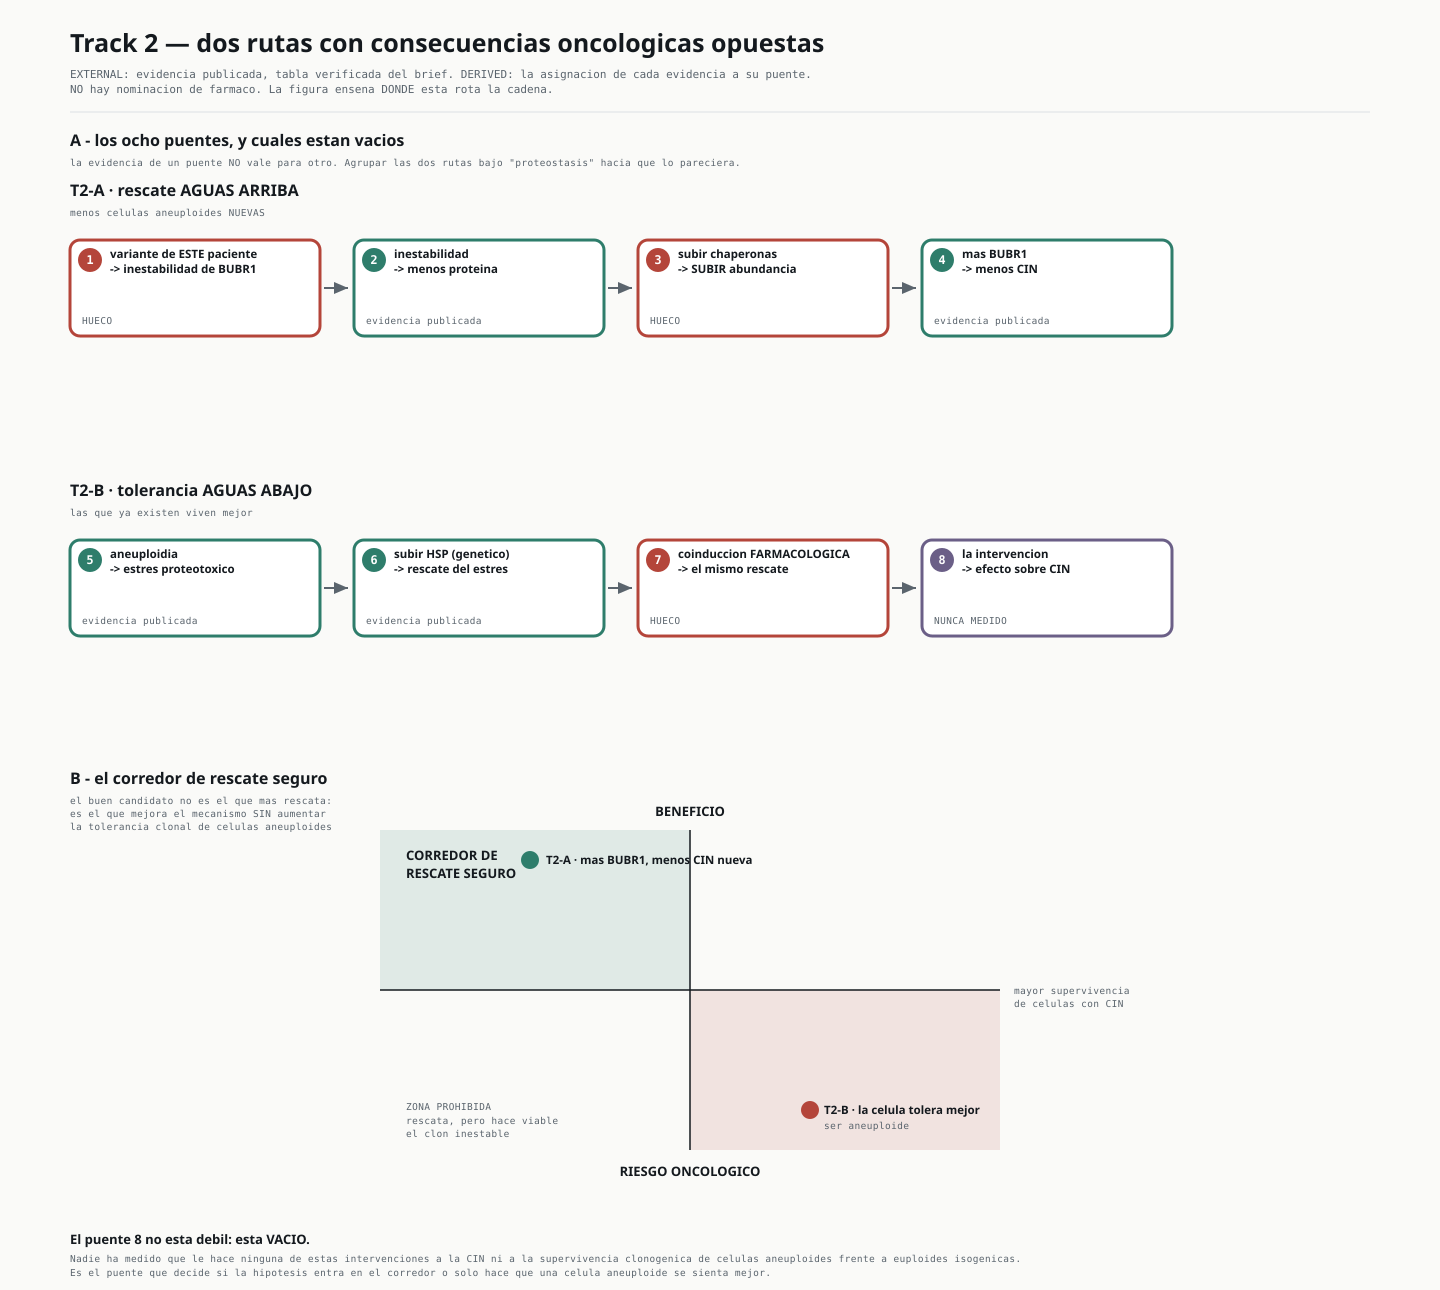

> **Figura principal 1 · los ocho puentes y el corredor**  
> `EXP-016` · **EXTERNAL+DERIVED**  
> *Qué enseña:* en rojo los puentes rotos, en morado el que nunca se midio. El panel B situa las dos rutas en el plano beneficio/riesgo: T2-A puede caer en el corredor; T2-B, por construccion, empuja hacia el eje de riesgo.  
> **Qué NO demuestra:** que T2-B este muerta ni que T2-A funcione. Ningun puente roto se ha cerrado como NEGATIVE: estan UNRESOLVED, que es distinto.  
> procedencia: `src/make_fig10.py → fig10_track2_bridges.svg · sha256[:12]=318c61ff0e9c`

In [3]:
fl.svg("figures/fig10_track2_bridges.svg",
       "Figura principal 1 · los ocho puentes y el corredor",
       "EXP-016", "EXTERNAL+DERIVED",
       "en rojo los puentes rotos, en morado el que nunca se midio. El panel B situa las dos "
       "rutas en el plano beneficio/riesgo: T2-A puede caer en el corredor; T2-B, por "
       "construccion, empuja hacia el eje de riesgo.",
       "que T2-B este muerta ni que T2-A funcione. Ningun puente roto se ha cerrado como "
       "NEGATIVE: estan UNRESOLVED, que es distinto.",
       generator="src/make_fig10.py")

## Resultado primario 2 · el puente 7, que es el corazón falsable

Búsqueda acotada con clasificación fijada de antemano:

| Clase | Encontrado |
|---|---|
| **DIRECT** — aneuploides + coinductor + rescate | **NINGUNA** |
| **NEAR** — coinducción en otro contexto proteotóxico | Sí — **no se admite como sustituto** |
| **GENETIC** — solo sobreexpresión | Sí — es toda la evidencia del puente 6 |
| **CONTRADICTORY** | **Dos, verificadas** |

**El contraejemplo (PMID 34481829).** En fibroblastos NPC1, la sobreexpresión de HSP70 redujo
el almacenamiento de colesterol; el coinductor **no lo reprodujo** hasta 500 µM — y el detalle
que más pesa: **no llegó a inducir HSP70**.

**La tensión (PMID 25205676).** En aneuploides humanos la inducción de la respuesta de choque
térmico está **al 50–60 %** del control. Lo que rescató fue **HSF1 constitutivamente activo**.

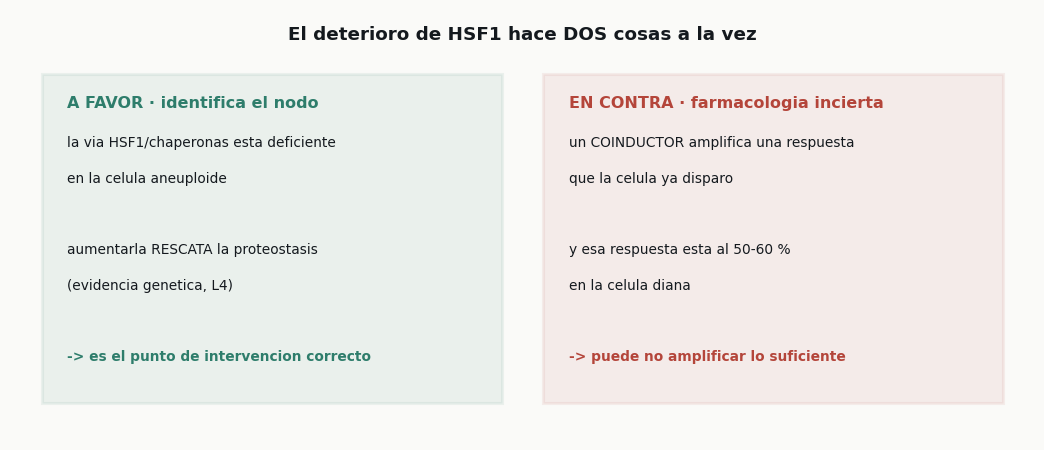

> **Figura principal 2 · la tension del puente 7**  
> `EXP-016b` · **EXTERNAL**  
> *Qué enseña:* el mismo hallazgo — inducion de HSR deficiente en aneuploides — es a la vez la razon para intervenir en esa via y el motivo por el que un coinductor podria no bastar. Lo que rescato en la literatura (HSF1 constitutivamente activo, sobreexpresion directa) PUENTEA el nodo deficiente en vez de amplificarlo.  
> **Qué NO demuestra:** que el coinductor vaya a fallar. Un coinductor amplifica y PROLONGA una respuesta ya iniciada; no exige una HSF1 intacta, y su mecanismo exacto no esta resuelto. Es UNRESOLVED, no NEGATIVE.  
> procedencia: `PMID 25205676 · PMID 34481829 · docs/EVIDENCE.md E18/E19`

In [4]:
fig, ax = plt.subplots(figsize=(9.6, 4.2))
ax.axis("off")
ax.set_xlim(0, 10); ax.set_ylim(0, 6)

# Los dos brazos de la tension, uno a cada lado
ax.text(5, 5.6, "El deterioro de HSF1 hace DOS cosas a la vez", ha="center",
        fontsize=12, fontweight="bold", color=fl.INK)
for x0, col, title, lines in (
    (0.3, fl.ALIVE, "A FAVOR · identifica el nodo",
     ["la via HSF1/chaperonas esta deficiente", "en la celula aneuploide",
      "", "aumentarla RESCATA la proteostasis", "(evidencia genetica, L4)",
      "", "-> es el punto de intervencion correcto"]),
    (5.2, fl.DEAD, "EN CONTRA · farmacologia incierta",
     ["un COINDUCTOR amplifica una respuesta", "que la celula ya disparo",
      "", "y esa respuesta esta al 50-60 %", "en la celula diana",
      "", "-> puede no amplificar lo suficiente"])):
    ax.add_patch(plt.Rectangle((x0, 0.5), 4.5, 4.6, fill=True, color=col, alpha=0.08,
                               ec=col, lw=2))
    ax.text(x0 + 0.25, 4.65, title, fontsize=10.5, fontweight="bold", color=col)
    for i, ln in enumerate(lines):
        ax.text(x0 + 0.25, 4.1 - i * 0.5, ln, fontsize=9,
                color=fl.INK if not ln.startswith("->") else col,
                fontweight="bold" if ln.startswith("->") else "normal")

fl.done(fig, "Figura principal 2 · la tension del puente 7", "EXP-016b", "EXTERNAL",
        "el mismo hallazgo — inducion de HSR deficiente en aneuploides — es a la vez la razon "
        "para intervenir en esa via y el motivo por el que un coinductor podria no bastar. "
        "Lo que rescato en la literatura (HSF1 constitutivamente activo, sobreexpresion "
        "directa) PUENTEA el nodo deficiente en vez de amplificarlo.",
        "que el coinductor vaya a fallar. Un coinductor amplifica y PROLONGA una respuesta "
        "ya iniciada; no exige una HSF1 intacta, y su mecanismo exacto no esta resuelto. Es "
        "UNRESOLVED, no NEGATIVE.",
        prov="PMID 25205676 · PMID 34481829 · docs/EVIDENCE.md E18/E19")

> **Formulación congelada:**
>
> *HSF1 impairment makes the pathway both mechanistically relevant and pharmacologically
> uncertain. Genetic augmentation can bypass the deficit; whether a stress-dependent
> pharmacological co-inducer can amplify the impaired endogenous response sufficiently
> remains unresolved.*

## Robustez · «Try to Kill It», y por qué es la mejor diapositiva

**La señal de eficacia y la señal de riesgo oncológico son la misma medición.**

Si una intervención rescata preferentemente a las células **más** aneuploides, eso es a la vez
la prueba de que el mecanismo es el propuesto **y** la prueba de que se está mejorando la
supervivencia clonogénica de células genómicamente inestables.

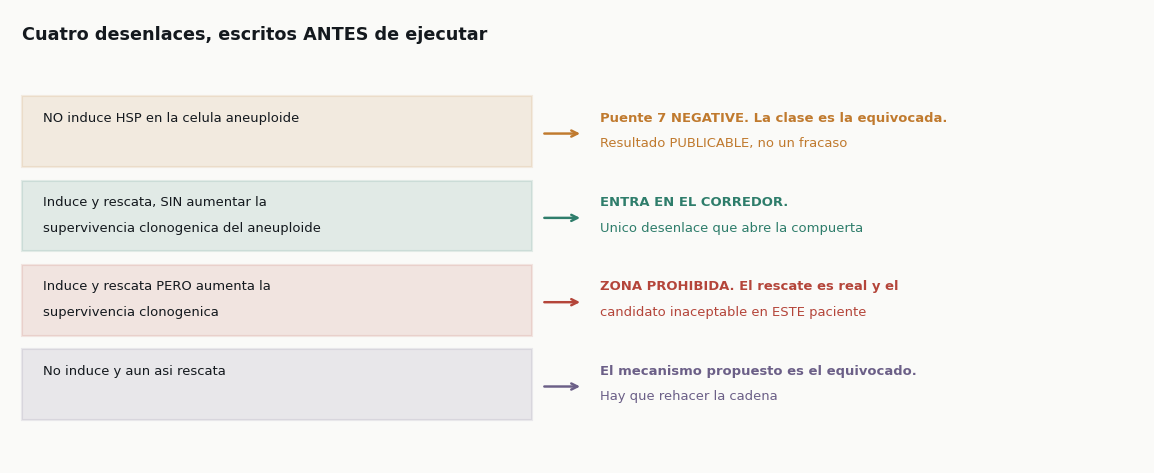

> **Figura de robustez · los cuatro desenlaces de Try to Kill It**  
> `EXP-016` · **DERIVED**  
> *Qué enseña:* el diseno minimo exige medir a la vez la eficacia (induccion de HSP, p62/TOMM20, importacion mitocondrial, ROS) y el riesgo (CIN, proliferacion, apoptosis, supervivencia clonogenica aneuploide frente a euploide isogenico). El TERCER desenlace es el que nadie mide, y es el que decide.  
> **Qué NO demuestra:** que el experimento se haya hecho. Es el diseno del siguiente experimento, no un resultado. Un diseno que mida solo la eficacia no es un experimento: es una demostracion.  
> procedencia: `docs/TRACK2_MECHANISM_MAP.md · brief §10.4`

In [5]:
OUTCOMES = [
 ("NO induce HSP en la celula aneuploide",
  "Puente 7 NEGATIVE. La clase es la equivocada.\nResultado PUBLICABLE, no un fracaso", fl.OPEN),
 ("Induce y rescata, SIN aumentar la\nsupervivencia clonogenica del aneuploide",
  "ENTRA EN EL CORREDOR.\nUnico desenlace que abre la compuerta", fl.ALIVE),
 ("Induce y rescata PERO aumenta la\nsupervivencia clonogenica",
  "ZONA PROHIBIDA. El rescate es real y el\ncandidato inaceptable en ESTE paciente", fl.DEAD),
 ("No induce y aun asi rescata",
  "El mecanismo propuesto es el equivocado.\nHay que rehacer la cadena", fl.VOID),
]
fig, ax = plt.subplots(figsize=(10.6, 4.4))
ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 4.6)
ax.text(0.1, 4.3, "Cuatro desenlaces, escritos ANTES de ejecutar", fontsize=11.5,
        fontweight="bold")
for i, (out, read, col) in enumerate(OUTCOMES):
    y = 3.35 - i * 0.86
    ax.add_patch(plt.Rectangle((0.1, y - 0.34), 4.5, 0.72, color=col, alpha=0.12, ec=col, lw=1.4))
    for j, ln in enumerate(out.split("\n")):
        ax.text(0.28, y + 0.12 - j * 0.26, ln, fontsize=8.6, color=fl.INK)
    ax.annotate("", xy=(5.05, y), xytext=(4.68, y),
                arrowprops=dict(arrowstyle="->", color=col, lw=1.6))
    for j, ln in enumerate(read.split("\n")):
        ax.text(5.2, y + 0.12 - j * 0.26, ln, fontsize=8.6, color=col,
                fontweight="bold" if j == 0 else "normal")

fl.done(fig, "Figura de robustez · los cuatro desenlaces de Try to Kill It", "EXP-016",
        "DERIVED",
        "el diseno minimo exige medir a la vez la eficacia (induccion de HSP, p62/TOMM20, "
        "importacion mitocondrial, ROS) y el riesgo (CIN, proliferacion, apoptosis, "
        "supervivencia clonogenica aneuploide frente a euploide isogenico). El TERCER "
        "desenlace es el que nadie mide, y es el que decide.",
        "que el experimento se haya hecho. Es el diseno del siguiente experimento, no un "
        "resultado. Un diseno que mida solo la eficacia no es un experimento: es una "
        "demostracion.",
        prov="docs/TRACK2_MECHANISM_MAP.md · brief §10.4")

## Evidencia contradictoria, declarada

| Afirmación | Contraevidencia |
|---|---|
| Subir HSP es terapéutico | Un coinductor **no fue efectivo** en ELA |
| Genético ≈ farmacológico | **PMID 34481829**: el genético rescató, el farmacológico no, y no indujo HSP70 |
| El rescate genético es universal | Dependió del **cariotipo**; una línea aneuploide no respondió |
| Ayudar a la célula aneuploide es bueno | **Es la definición oncológica de un paso temprano de tumorigénesis** |

## Decisión

| | |
|---|---|
| **Clase superviviente principal** | Modulación de proteostasis y chaperonas — **entre las seis evaluadas** |
| **T2-A · aguas arriba** | **UNRESOLVED** — bloqueada por los puentes 1 y 3 |
| **T2-B · aguas abajo** | **UNRESOLVED** — bloqueada por los puentes 7 y 8 |
| **Nominación de fármaco** | **NINGUNA** |
| Proteasoma · poda clonal | **NEGATIVE** |
| Estabilización por acetilación · senolíticos | **PARKED** |

**La compuerta del fármaco exige las cinco:** estatus aprobado · proximidad mecanística a un
puente nombrado · evidencia **de ese** puente · predicción de rescate falsable · contra-test
explícito de CIN/tumor. **Hoy ninguna candidata las reúne.**

### Qué NO demuestra este notebook

Que la clase sea la correcta · que exista un fármaco que sirva · que rescatar sea seguro. Y
tampoco que se haya barrido el espacio terapéutico completo: se evaluaron **seis clases
elegidas desde la cadena mecanística del caso**.

### Falsificador

El experimento de arriba, con sus cuatro desenlaces preescritos. Dos de los cuatro **matan la
hipótesis**, y eso es lo que la hace falsable.

### Next Best Experiment

Par isogénico aneuploide/euploide ± coinductor candidato, con **control positivo genético**
(HSF1 constitutivamente activo) y **lectura obligatoria de si el fármaco induce HSP** — porque
el contraejemplo enseña que puede **no** inducir, y sin medirlo no se sabe si falló el fármaco
o la hipótesis. Midiendo a la vez CIN y supervivencia clonogénica.